# 02 – Churn Visualisations and Insights

### Objectives
* Load and inspect the cleaned credit card customer dataset (`data/processed/cleaned_bank_churners.csv`).
* Explore demographic and behavioral patterns associated with customer churn.
* Create visualizations to identify key churn drivers.
* Formulate data-driven business recommendations to improve customer retention.

## Environment Setup & Data Import

I initialize the visualization environment by loading the preprocessed dataset (`cleaned_bank_churners.csv`) generated from Notebook 01.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Load preprocessed dataset from ETL stage
df = pd.read_csv('../data/processed/cleaned_bank_churners.csv')
# Verify shape and contents
print(f"✅ Clean dataset loaded: {df.shape[0]} rows | {df.shape[1]} columns")
display(df.head())

✅ Clean dataset loaded: 10127 rows | 20 columns


,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,churn
0,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0
1,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0
2,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0
3,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0
4,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0



## Visual 1: Overall Customer Churn Rate & Class Imbalance

**Goal:** Establish the baseline customer churn rate across the entire dataset ($N = 10,127$) 
to evaluate class distributions.

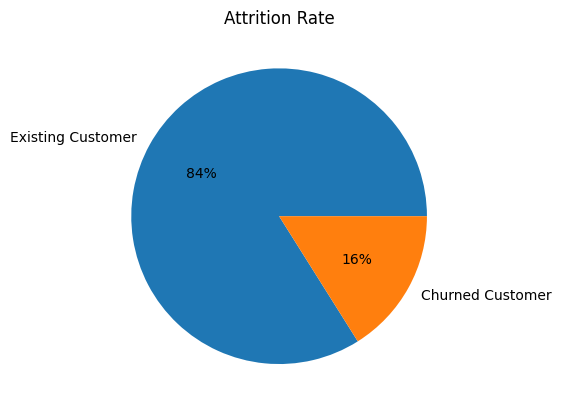

In [17]:
# Baseline churn pie chart using the 'churn' column
categorical_count = df['churn'].map({0: 'Existing Customer', 1: 'Churned Customer'}).value_counts(normalize=True)

plt.pie(x=categorical_count, labels=categorical_count.index, autopct='%1.0f%%')
plt.title("Attrition Rate")
plt.show()


Before analyzing individual predictor variables, I inspect the overall distribution of our target variable (`churn`).

### Key Insights: Target Churn Distribution
* **Baseline Churn Rate:** Out of $10,127$ customers, **$16.07\%$ ($1,627$ customers)** have churned, while **$83.93\%$ ($8,500$ customers)** remain active.
* In retail banking, a 16.1% annual churn rate is relatively high. Losing nearly 1 in 6 credit card customers represents significant revenue loss from missed transaction fees, interest payments, and annual renewal charges.

## Visual 2.1 Customer Age Distribution by Churn Status

I evaluate age density curves across existing and churned cohorts to identify whether specific age demographics carry higher attrition risks.

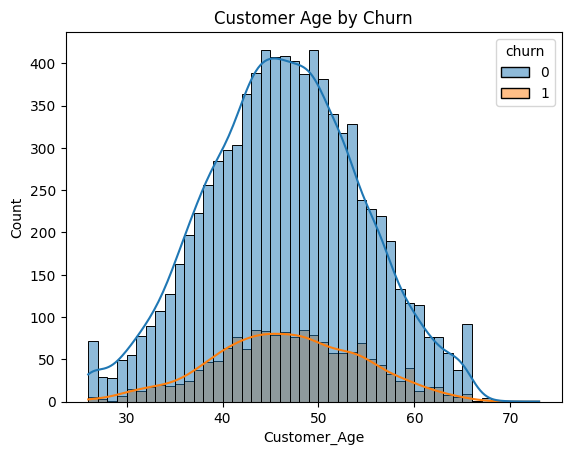

In [18]:
sns.histplot(data=df, x='Customer_Age', hue='churn', kde=True)
plt.title("Customer Age by Churn")
plt.show()

### Key Insights: Customer Age Profile

*  Both active and churned customer groups exhibit identical bell-shaped distributions, peaking between **40 and 50 years of age** (with an overall mean and median of approximately **46 years**).
* There is no significant age group skewing toward higher churn rates. Younger cardholders (under 30) and older cardholders (over 60) display proportional attrition rates to middle-aged cardholders.

## Visual 2.2 Churn Rate Across Income Categories

I cross-tabulate churn percentages across income brackets to measure if earning capacity correlates with retention

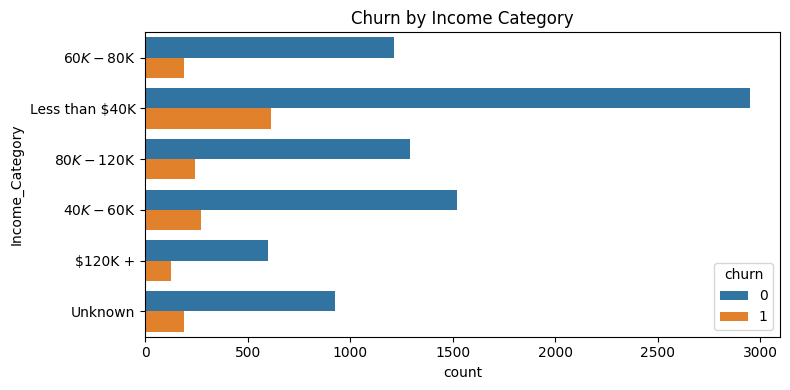

In [23]:
# Income category count by churn
plt.figure(figsize=(8, 4))
sns.countplot(data=df, y='Income_Category', hue='churn')
plt.title("Churn by Income Category")
plt.tight_layout()
plt.show()

### Key Insights: Salary & Income Tiers

* Churn rates remain remarkably stable across all salary tiers:
  * **Less than $40K:** 17.2% churn
  * **$40K – $60K:** 15.1% churn
  * **$60K – $80K:** 13.5% churn
  * **$80K – $120K:** 15.8% churn
  * **$120K+:** 17.2% churn
* Income level is not a primary driver of account cancellations. High-net-worth customers churn at the same rate as entry-level customers, meaning retention strategies should focus on usage and engagement rather than income-tier segmentation.

## Visual 2.3 Churn Rate by Marital Status
  
I measure attrition across marital categories to check for segment-specific departure patterns.

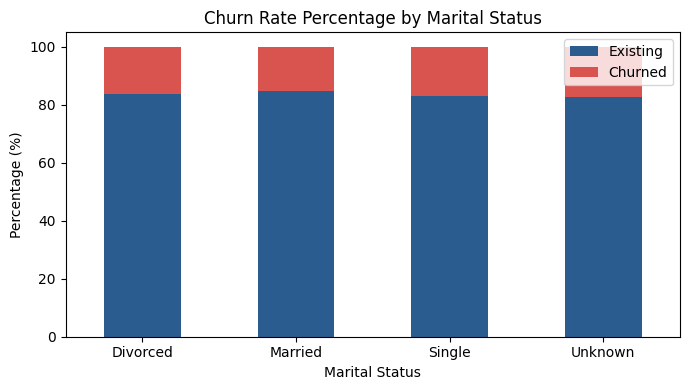

In [27]:
# 100% Stacked Bar Chart for Marital Status
marital_churn = pd.crosstab(df['Marital_Status'], df['churn'], normalize='index') * 100

marital_churn.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d9534f'], figsize=(7, 4))
plt.title("Churn Rate Percentage by Marital Status")
plt.ylabel("Percentage (%)")
plt.xlabel("Marital Status")
plt.legend(['Existing', 'Churned'], loc='upper right')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Insights: Marital Status Dynamics

* **Negligible Variance Across Categories:**
  * **Single:** 16.9% churn
  * **Divorced:** 16.2% churn
  * **Married:** 15.1% churn
  * **Unknown:** 16.8% churn
* Marital status play an insignificant role in account closure decisions. Married customers show a minor 1.8% higher retention edge over single customers, but this difference is statistically marginal.

## Visual 2.4 Churn rate by Gender
 
To evaluate whether gender plays a structural role in card retention, I calculate the observed churn rate (%) across male and female account holders. 

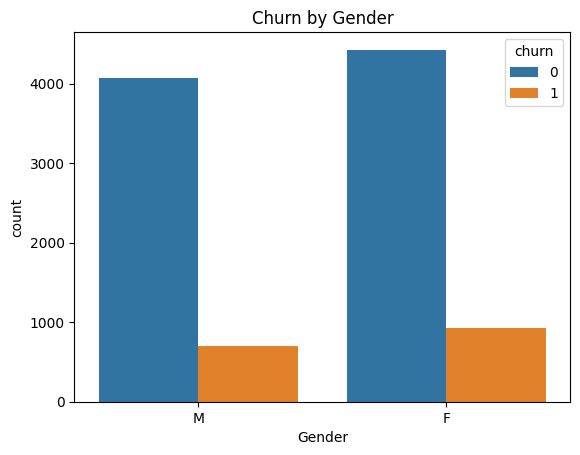

In [24]:
sns.countplot(data=df, x='Gender', hue='churn')
plt.title("Churn by Gender")
plt.show()

### Key Insights: Gender Proportions
**Female Cohort:** 82.6% Retained vs. 17.4% Churned.

**Male Cohort:** 85.4% Retained vs. 14.6% Churned.

Both genders hover very close to the overall 16.1% baseline. Gender is not a strong driver of churn.

## Key Takeaway:
 Personal demographic traits (age, income, marital status) are weak predictors of churn. 

# 3. Behavioral & Financial Feature Analysis
 
While demographic traits show low predictive power, financial activity and behavioral engagement directly expose account decay. By examining transaction volumes, spending amounts, revolving balances, and product holdings, I identify the exact operational thresholds where customer attrition occurs.

## Visual 3.1 Transactional Amount vs. Transaction Count by Churn

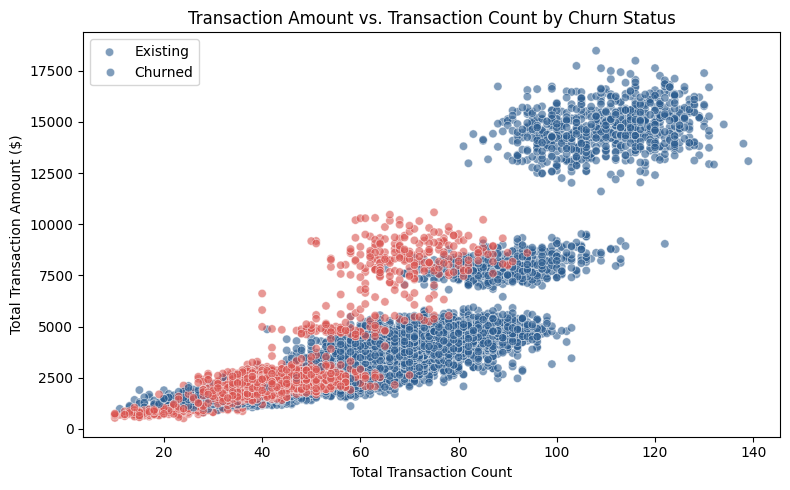

In [29]:
# Scatter plot: Total Transaction Amount vs. Transaction Count
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, 
    x='Total_Trans_Ct', 
    y='Total_Trans_Amt', 
    hue='churn', 
    palette=['#2b5c8f', '#d9534f'],
    alpha=0.6
)

plt.title("Transaction Amount vs. Transaction Count by Churn Status")
plt.xlabel("Total Transaction Count")
plt.ylabel("Total Transaction Amount ($)")
plt.legend(['Existing', 'Churned'], loc='upper left')
plt.tight_layout()
plt.show()

### Key Insights
Customers cancel their cards when they stop using them. Customers with fewer than 50 Total_Trans_Ct or under $2,500 in Total_Trans_Amt are at the highest risk of churn. Customers who maintain over 60 transactions almost never leave.

## Visual 3.2 Credit Utilization & Account Balance (Box Plot & Histogram)
I visualize numerical distributions across churn groups using box plots and histograms to inspect median shifts and zero-balance patterns.

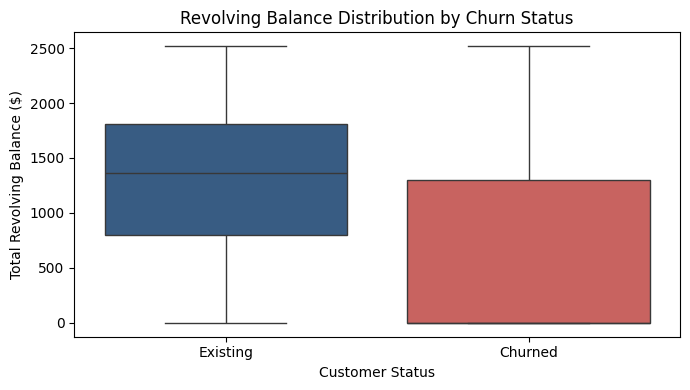

In [31]:
# Box plot: Revolving Balance by Churn Status
plt.figure(figsize=(7, 4))
sns.boxplot(
    data=df, 
    x='churn', 
    y='Total_Revolving_Bal', 
    hue='churn', 
    palette=['#2b5c8f', '#d9534f'],
    legend=False
)

plt.title("Revolving Balance Distribution by Churn Status")
plt.xticks([0, 1], ['Existing', 'Churned'])
plt.xlabel("Customer Status")
plt.ylabel("Total Revolving Balance ($)")
plt.tight_layout()
plt.show()

### Key Insights
A drop to $0 in Total_Revolving_Bal is a major early warning sign. Customers usually stop carrying a balance and abandon their card long before officially closing the account.

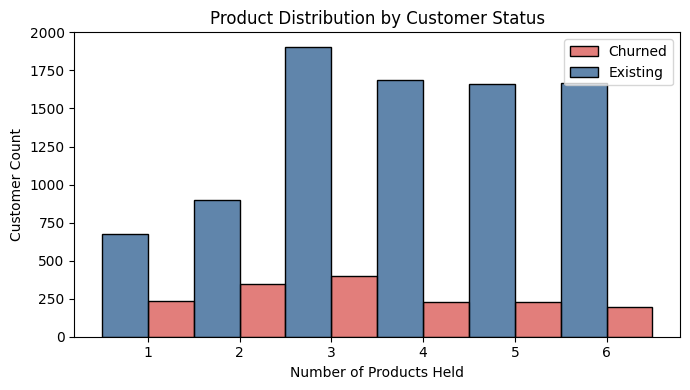

In [32]:
# Histogram: Total Relationship Count (Products Held)
plt.figure(figsize=(7, 4))
sns.histplot(
    data=df, 
    x='Total_Relationship_Count', 
    hue='churn', 
    multiple='dodge', 
    discrete=True,
    palette=['#2b5c8f', '#d9534f']
)

plt.title("Product Distribution by Customer Status")
plt.xlabel("Number of Products Held")
plt.ylabel("Customer Count")
plt.legend(['Churned', 'Existing'], loc='upper right')
plt.tight_layout()
plt.show()

### Key Insight
Retention increases as Total_Relationship_Count grows. Customers with a Total_Relationship_Count of 1 or 2 leave at high rates, while customers with 5 or 6 products almost never leave

## Visual 3.3 Total Transaction Amount vs Months on Book by Churn

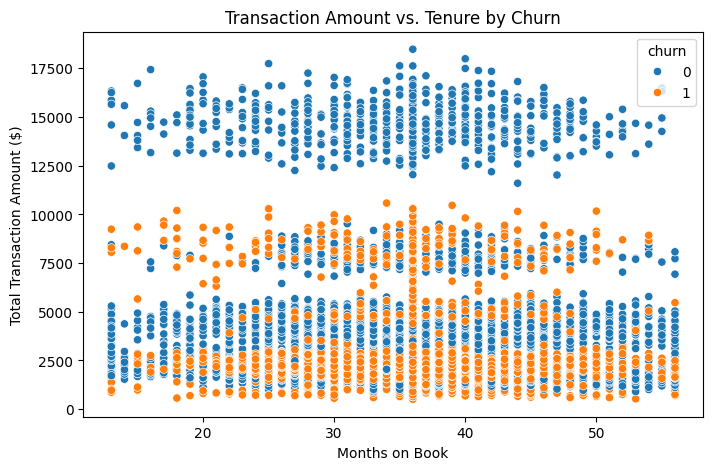

In [39]:
# Scatter Plot: Spend vs Tenure
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Months_on_book', y='Total_Trans_Amt', hue='churn')
plt.title("Transaction Amount vs. Tenure by Churn")
plt.xlabel("Months on Book")
plt.ylabel("Total Transaction Amount ($)")
plt.show()

### Key Insights
Having a high number of Months_on_book does not protect against churn. Long-term customers with 36+ Months_on_book leave at the exact same rates as newer customers if their spending drops.

### Summary of Results
**Card Use Determines Churn:** People cancel their cards when they stop using them—not because they are new or old customers. Customers with under 50 purchases or spending less than $2,500 a year are at the highest risk of leaving.

**Long-Time Customers Still Leave:** Having an account for 3 or 4 years does not keep a customer safe. If a long-time customer stops spending, they leave just like new customers do.

$0 Balance is a Warning Sign: Before closing an account, customers usually stop carrying a balance and let the card sit empty ($0 balance).

**More Products = Better Retention:** Customers who only have 1 or 2 products with the bank (like just a credit card) leave at high rates. Customers who use 5 or 6 bank products almost never leave.

# Correlation Analysis

Goal is to understand how numerical features relate to one another and to customer churn, we compute the correlation matrix and visualize it with a heatmap.

### Correlation Heatmap

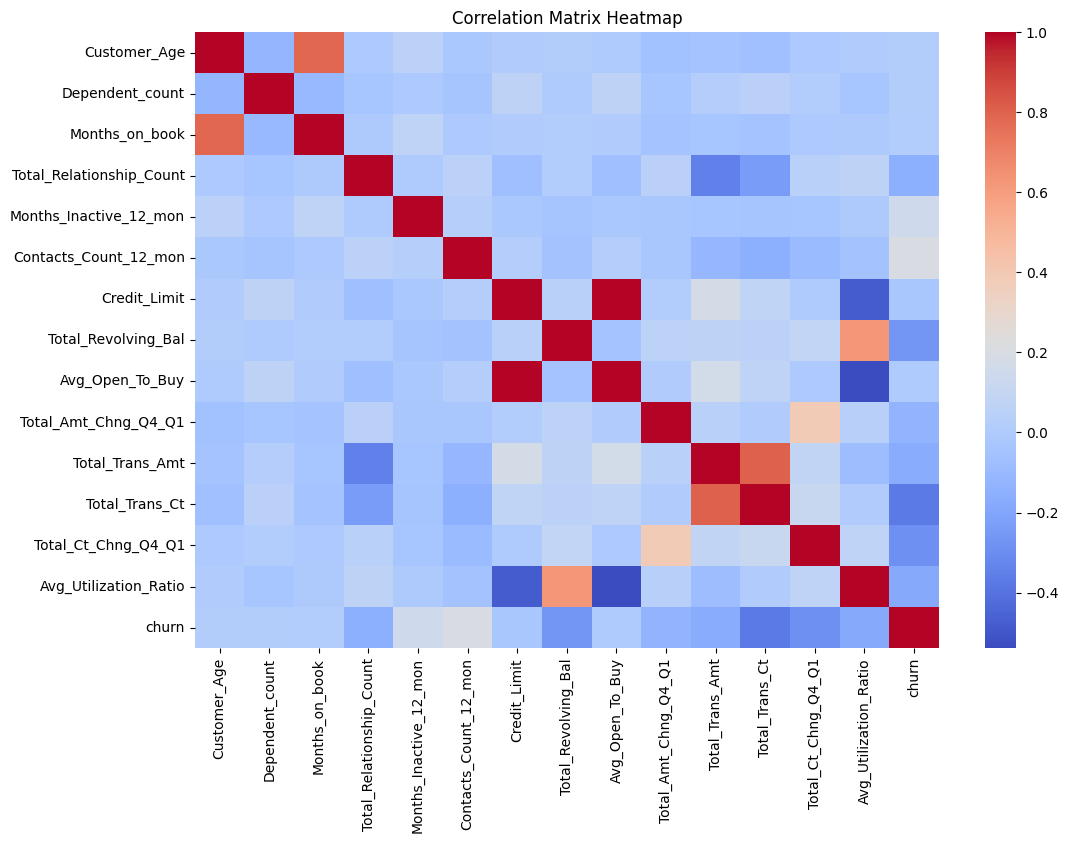

In [40]:
# Select numerical columns for correlation analysis
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# Compute correlation matrix
corr_matrix = numeric_df.corr()

# Plot clean correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)
plt.title("Correlation Matrix Heatmap")
plt.show()

### Top Correlation with Churn

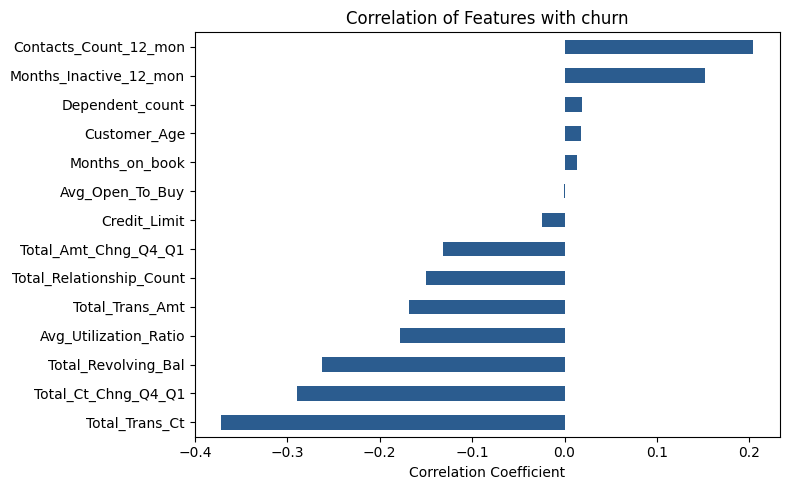

In [41]:
# Correlation of each feature with the churn column
churn_corr = corr_matrix['churn'].drop('churn').sort_values()

# Simple horizontal bar chart
plt.figure(figsize=(8, 5))
churn_corr.plot(kind='barh', color='#2b5c8f')
plt.title("Correlation of Features with churn")
plt.xlabel("Correlation Coefficient")
plt.tight_layout()
plt.show()

### Key Insights
**Total_Trans_Ct & Total_Trans_Amt (Strongest Negative Correlation):**
These two features have the strongest negative relationship with churn. As spending and transaction counts go up, churn goes down significantly.

**Avg_Utilization_Ratio & Total_Revolving_Bal:**
Both show a strong negative correlation with churn. Lower card usage and lower balances signal that a customer is getting ready to leave.

**Months_on_book (Near-Zero Correlation):**
Months_on_book shows almost zero correlation with churn, proving once again that customer account age has no impact on whether someone stays or cancels.

README : [text](../README.md)